# 10. Monte Carlo methods

**Track:** advanced &nbsp;·&nbsp; **Prerequisites:** Chapters 5 and 7

**Reading:** Bevington & Robinson, ch. 5 · Rouaud, ch. III.D · JCGM 101:2008
(GUM Supplement 1) · Press *et al.*, *Numerical Recipes*, ch. 7

Monte Carlo simulation runs through this whole repository: to check
propagation formulas, to verify the coverage of intervals, to propagate
distributions through nonlinear models. This chapter looks at the method
itself.

1. Pseudo-random numbers and reproducibility.
2. How to draw samples from a given distribution: inverse transform and
   rejection sampling.
3. Correlated inputs.
4. The accuracy of Monte Carlo results: how it scales with the number of
   samples, and how many samples are needed for a mean, a standard
   deviation or a 95 % interval.
5. Variance reduction by stratified and Latin hypercube sampling.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

try:
    import errprop as ep
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    import errprop as ep

ep.use_style()
rng = np.random.default_rng(110)

## 10.1 Pseudo-random numbers

Computers generate *pseudo*-random numbers: a deterministic sequence that
passes statistical tests of randomness. Two properties matter in practice.

* **Quality.** Modern generators (NumPy's default is PCG64) have periods
  far longer than any simulation and no detectable correlations in ordinary
  use. Older linear congruential generators, still found in some software,
  can have short periods and correlations between successive numbers.
* **Reproducibility.** The sequence is fixed by a *seed*. Every notebook in
  this repository starts with `np.random.default_rng(seed)`, so that its
  results can be reproduced exactly. A result that changes by more than its
  stated Monte Carlo uncertainty when the seed changes has been reported
  with too few samples.

## 10.2 Sampling from a distribution

Generators produce uniform numbers $u$ on $[0, 1)$; everything else is built
from them.

**Inverse transform.** If $F(x)$ is the cumulative distribution function of
the target distribution, then $x = F^{-1}(u)$ has that distribution, because
$P(x \le a) = P(u \le F(a)) = F(a)$. For the exponential distribution,
$F(x) = 1 - e^{-\lambda x}$ and $x = -\ln(1-u)/\lambda$; for the Cauchy
distribution, $x = x_0 + \tfrac{\Gamma}{2}\tan[\pi(u - \tfrac12)]$.

**Rejection sampling.** When $F^{-1}$ is not available, choose a simpler
envelope distribution $g(x)$ and a constant $M$ with $p(x) \le M g(x)$
everywhere. Draw $x$ from $g$ and a uniform $u$; accept $x$ if
$u\,M g(x) < p(x)$. The accepted values follow $p(x)$, and the fraction
accepted is $1/M$, so a tight envelope matters. Below, the angular
distribution $p(\theta) \propto 1 + \cos^2\theta$ (dipole radiation) is
sampled with a uniform envelope.

**Normal variables.** The Box–Muller transform turns two uniform numbers
into two independent standard normal ones:
$z_1 = \sqrt{-2\ln u_1}\cos 2\pi u_2$, $z_2 = \sqrt{-2\ln u_1}\sin 2\pi u_2$.
Libraries use faster methods, but the idea is the same.

In [2]:
u = rng.random(200_000)
lam = 0.5
x_exp = -np.log(1 - u) / lam
x_cau = np.tan(np.pi * (u - 0.5))
print(f"exponential by inverse transform: mean {x_exp.mean():.3f} (expected {1 / lam}), std {x_exp.std():.3f} (expected {1 / lam})")
print(f"Cauchy by inverse transform: median {np.median(x_cau):+.4f}, quartiles {np.quantile(x_cau, [0.25, 0.75]).round(3)} (expected -1, 1)")

def sample_dipole(n, rng):
    """theta in [0, pi] with density proportional to (1 + cos^2 theta) sin theta."""
    out = np.empty(0)
    tries = accepted = 0
    while out.size < n:
        th = rng.uniform(0, np.pi, 2 * n)
        p = (1 + np.cos(th)**2) * np.sin(th)
        acc = rng.random(2 * n) * 2.0 < p          # envelope: constant 2 >= max of p
        out = np.concatenate([out, th[acc]])
        tries += 2 * n
        accepted += acc.sum()
    return out[:n], accepted / tries

theta, eff = sample_dipole(200_000, rng)
print(f"rejection sampling: acceptance {eff:.3f};  <cos^2 theta> = {np.mean(np.cos(theta)**2):.4f} (exact 0.4)")

u1, u2 = rng.random(100_000), rng.random(100_000)
z1 = np.sqrt(-2 * np.log(u1)) * np.cos(2 * np.pi * u2)
print(f"Box-Muller: mean {z1.mean():+.4f}, std {z1.std():.4f}, kurtosis excess {stats.kurtosis(z1):+.3f}")

exponential by inverse transform: mean 2.007 (expected 2.0), std 2.002 (expected 2.0)
Cauchy by inverse transform: median +0.0072, quartiles [-0.998  1.011] (expected -1, 1)
rejection sampling: acceptance 0.425;  <cos^2 theta> = 0.3999 (exact 0.4)
Box-Muller: mean +0.0013, std 1.0040, kurtosis excess +0.002


The acceptance rate of the dipole sampler is about 0.42 (the area under
$p$ divided by the area of the envelope box), so more than half the effort
is discarded; a better envelope would raise it.

## 10.3 Correlated inputs

To propagate correlated input quantities (Chapter 12) we need samples with
a given covariance matrix $\mathsf C$. Factor it as $\mathsf C = \mathsf L\mathsf L^{\mathsf T}$
(Cholesky decomposition) and set $\boldsymbol x = \boldsymbol\mu + \mathsf L\boldsymbol z$
with $\boldsymbol z$ a vector of independent standard normal numbers. Then
$\langle\delta\boldsymbol x\,\delta\boldsymbol x^{\mathsf T}\rangle = \mathsf L\langle\boldsymbol z\boldsymbol z^{\mathsf T}\rangle\mathsf L^{\mathsf T} = \mathsf C$.
This is what `ep.monte_carlo(..., cov=C)` does internally (through NumPy's
`multivariate_normal`).

In [3]:
C = np.array([[1.0, 0.8, 0.2], [0.8, 1.0, 0.5], [0.2, 0.5, 1.0]]) * np.outer([0.1, 0.2, 0.3], [0.1, 0.2, 0.3])
L = np.linalg.cholesky(C)
xs = (L @ rng.normal(size=(3, 200_000))).T
print("target correlation:\n", np.round(C / np.sqrt(np.outer(np.diag(C), np.diag(C))), 3))
print("sample correlation:\n", np.round(np.corrcoef(xs.T), 3))

target correlation:
 [[1.  0.8 0.2]
 [0.8 1.  0.5]
 [0.2 0.5 1. ]]
sample correlation:
 [[1.    0.8   0.201]
 [0.8   1.    0.5  ]
 [0.201 0.5   1.   ]]


## 10.4 How accurate is a Monte Carlo result?

A Monte Carlo estimate is itself a statistical estimate from $M$ samples,
with an uncertainty that falls as $1/\sqrt M$ whatever the number of input
variables. This dimension-independence is what makes the method so useful.
For $M$ independent samples of an output with standard deviation $\sigma$:

* the **mean** has standard error $\sigma/\sqrt M$;
* the **standard deviation** has relative standard error about
  $1/\sqrt{2M}$ for normal outputs (Section 4.3), larger for heavy-tailed
  ones;
* a **quantile** $q_p$ (for example the 2.5 % and 97.5 % points of a 95 %
  interval) has standard error

  $$ u(q_p) \approx \frac{1}{f(q_p)}\sqrt{\frac{p(1-p)}{M}} , $$

  where $f$ is the probability density at the quantile. Since $f$ is small in
  the tails, tail quantiles converge slowly.

JCGM 101 recommends running the simulation until the quantities to be
reported are stable to the number of digits quoted, and suggests at least
$M = 10^6$ trials for a 95 % interval when nothing better is known. The
simulation below checks the three formulas.

In [4]:
M_values = np.array([100, 1_000, 10_000, 100_000])
n_rep = 400
print("    M     u(mean)    sigma/sqrt(M)    u(std)/std   1/sqrt(2M)    u(q97.5)   formula")
mc_acc = []
for M in M_values:
    smp = rng.normal(0, 1, (n_rep, M))
    means, sds = smp.mean(axis=1), smp.std(axis=1, ddof=1)
    q = np.quantile(smp, 0.975, axis=1)
    f_q = stats.norm.pdf(1.959964)
    q_formula = np.sqrt(0.975 * 0.025 / M) / f_q
    mc_acc.append((M, means.std(), sds.std(), q.std(), q_formula))
    print(f"{M:7d}   {means.std():.5f}     {1 / np.sqrt(M):.5f}         {sds.std():.4f}      {1 / np.sqrt(2 * M):.4f}      {q.std():.4f}    {q_formula:.4f}")

    M     u(mean)    sigma/sqrt(M)    u(std)/std   1/sqrt(2M)    u(q97.5)   formula
    100   0.09711     0.10000         0.0742      0.0707      0.2462    0.2671
   1000   0.03207     0.03162         0.0212      0.0224      0.0841    0.0845


  10000   0.01060     0.01000         0.0074      0.0071      0.0276    0.0267


 100000   0.00306     0.00316         0.0023      0.0022      0.0083    0.0084


For $M = 10^4$ the 97.5 % point is uncertain by about 0.03 standard
deviations, enough to change the second significant figure of an expanded
uncertainty. Reporting an interval to two significant figures needs
$M \approx 10^5$ to $10^6$.

## 10.5 Variance reduction: stratified and Latin hypercube sampling

Plain Monte Carlo can waste samples: by chance some regions of the input
space are crowded and others empty. **Stratified sampling** divides the
range of each input into $M$ equally probable strata and draws exactly one
sample from each; for a single input this removes most of the sampling
noise. With several inputs, full stratification would need $M^k$ samples.
**Latin hypercube sampling** (McKay, Beckman and Conover, 1979) stratifies
each input separately and pairs the strata by random permutations, so each
input is perfectly stratified with only $M$ samples.

The gain is largest for outputs that depend additively on the inputs and
disappears for strongly interacting ones. Below, the standard deviation of
the cylinder density of Chapter 3 (three inputs, nearly additive in the
logarithm) is estimated with each method.

In [5]:
def lhs_normal(M, means, sds, rng):
    k = len(means)
    out = np.empty((M, k))
    for j in range(k):
        strata = (rng.permutation(M) + rng.random(M)) / M
        out[:, j] = means[j] + sds[j] * stats.norm.ppf(strata)
    return out

density = lambda m, d, h: 4 * m / (np.pi * d**2 * h)
mu_in = np.array([23.45e-3, 9.98e-3, 35.10e-3])
sd_in = np.array([0.01e-3, 0.02e-3, 0.05e-3])
_, u_lin = ep.propagate(density, mu_in, sd_in)

print("    M     spread of the estimated u(rho): plain MC    Latin hypercube    gain in M")
lhs_rows = []
for M in (50, 200, 1000, 5000):
    est_mc, est_lhs = [], []
    for _ in range(300):
        X = rng.normal(mu_in, sd_in, (M, 3))
        est_mc.append(density(*X.T).std(ddof=1))
        Xl = lhs_normal(M, mu_in, sd_in, rng)
        est_lhs.append(density(*Xl.T).std(ddof=1))
    a, b = np.std(est_mc) / u_lin, np.std(est_lhs) / u_lin
    lhs_rows.append((M, a, b))
    print(f"{M:6d}                    {a:.4f}              {b:.4f}            {(a / b)**2:5.1f}")

    M     spread of the estimated u(rho): plain MC    Latin hypercube    gain in M
    50                    0.0986              0.0540              3.3
   200                    0.0493              0.0259              3.6


  1000                    0.0212              0.0104              4.2


  5000                    0.0105              0.0051              4.2


For this nearly additive model, Latin hypercube sampling estimates the
output standard deviation as precisely as plain Monte Carlo with about four
times as many samples. (For the *mean* of an additive model the gain is far
larger; for the standard deviation it is limited by the squared terms.) The gain matters when each model evaluation is expensive (a
finite-element run, a molecular simulation). For cheap models, plain
Monte Carlo with more samples is simpler and its statistical error is easier
to state. Note that the samples of a Latin hypercube are not independent,
so the simple error formulas of Section 10.4 do not apply to it; repeat the
whole design with different seeds to estimate its error, as done here.

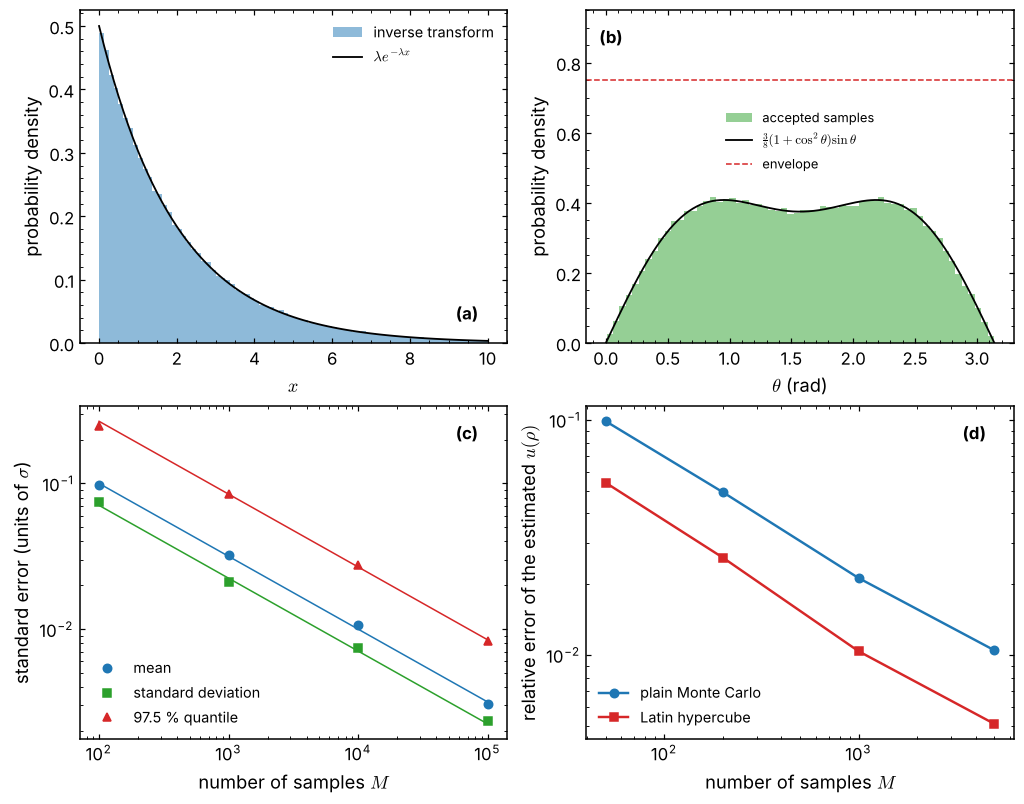

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(9.2, 7.2))

ax = axes[0, 0]
bins = np.linspace(0, 10, 81)
ax.hist(x_exp, bins=bins, density=True, color="C0", alpha=0.5, label="inverse transform")
ax.plot(bins, lam * np.exp(-lam * bins), "k", lw=1.2, label=r"$\lambda e^{-\lambda x}$")
ax.set_xlabel("$x$"); ax.set_ylabel("probability density")
ax.legend(loc="upper right"); ep.panel_label(ax, "(a)", y=0.12, x=0.88)

ax = axes[0, 1]
tt = np.linspace(0, np.pi, 300)
ax.hist(theta, bins=60, density=True, color="C2", alpha=0.5, label="accepted samples")
ax.plot(tt, 3 / 8 * (1 + np.cos(tt)**2) * np.sin(tt), "k", lw=1.2, label=r"$\frac{3}{8}(1 + \cos^2\theta)\sin\theta$")
ax.axhline(2 * 3 / 8, color="C3", ls="--", lw=1, label="envelope")
ax.set_xlabel(r"$\theta$ (rad)"); ax.set_ylabel("probability density")
ax.set_ylim(0, 0.95); ax.legend(loc="lower center", bbox_to_anchor=(0.5, 0.48), fontsize=8.5); ep.panel_label(ax, "(b)")

ax = axes[1, 0]
Ms = np.array([r[0] for r in mc_acc])
ax.loglog(Ms, [r[1] for r in mc_acc], "o", color="C0", label="mean")
ax.loglog(Ms, [r[2] for r in mc_acc], "s", color="C2", label="standard deviation")
ax.loglog(Ms, [r[3] for r in mc_acc], "^", color="C3", label="97.5 % quantile")
ax.loglog(Ms, 1 / np.sqrt(Ms), "C0-", lw=1)
ax.loglog(Ms, 1 / np.sqrt(2 * Ms), "C2-", lw=1)
ax.loglog(Ms, [r[4] for r in mc_acc], "C3-", lw=1)
ax.set_xlabel("number of samples $M$"); ax.set_ylabel(r"standard error (units of $\sigma$)")
ax.legend(loc="lower left"); ep.panel_label(ax, "(c)", x=0.88)

ax = axes[1, 1]
Ml = np.array([r[0] for r in lhs_rows])
ax.loglog(Ml, [r[1] for r in lhs_rows], "o-", color="C0", label="plain Monte Carlo")
ax.loglog(Ml, [r[2] for r in lhs_rows], "s-", color="C3", label="Latin hypercube")
ax.set_xlabel("number of samples $M$"); ax.set_ylabel(r"relative error of the estimated $u(\rho)$")
ax.legend(loc="lower left"); ep.panel_label(ax, "(d)", x=0.88)
plt.show()

**(a)** Exponential samples from uniform numbers by the inverse transform.
**(b)** Rejection sampling of a dipole angular distribution with a flat
envelope. **(c)** Standard errors of Monte Carlo estimates of the mean, the
standard deviation and the 97.5 % quantile of a normal output (symbols:
repeated simulations; lines: formulas of Section 10.4). **(d)** Precision of
the estimated output uncertainty with plain and Latin hypercube sampling.

## Summary

* Seed every simulation; a result should be stable to well within its
  Monte Carlo error when the seed changes.
* Inverse transform and rejection sampling generate any distribution from
  uniform numbers; Cholesky factors generate correlated normals.
* Monte Carlo errors fall as $1/\sqrt M$ for every quantity, but with very
  different constants: tail quantiles need far more samples than means.
* Latin hypercube sampling can save many model evaluations for nearly
  additive models; estimate its error by repeating the design.

## References

* JCGM 101:2008, *Evaluation of measurement data, Supplement 1 to the
  "Guide to the expression of uncertainty in measurement": Propagation of
  distributions using a Monte Carlo method*.
* W. H. Press, S. A. Teukolsky, W. T. Vetterling and B. P. Flannery,
  *Numerical Recipes*, 3rd ed. (Cambridge University Press, 2007), ch. 7.
* M. D. McKay, R. J. Beckman and W. J. Conover, "A comparison of three
  methods for selecting values of input variables in the analysis of output
  from a computer code", *Technometrics* **21**, 239 (1979).

## Exercises

1. Sample the Rayleigh distribution $p(r) = (r/\sigma^2)e^{-r^2/2\sigma^2}$ by
   the inverse transform and check its mean $\sigma\sqrt{\pi/2}$.
2. Improve the envelope of the dipole sampler (for example $g \propto \sin\theta$,
   sampled by inverse transform) and compare the acceptance rates.
3. A covariance matrix estimated from data is sometimes not positive
   definite, and the Cholesky factorisation fails. Construct such a matrix
   from three pairwise correlations and explain why it cannot be a valid
   covariance matrix.
4. How many samples are needed to estimate the 99.5 % quantile of a
   normal output to within 0.01 standard deviations?
5. Repeat the comparison of Section 10.5 for the strongly nonlinear ratio
   $a/b$ of Section 12.4 ($b = 1.0 \pm 0.3$). Does Latin hypercube sampling
   still help?

---

**Previous:** [9. Outliers and the rejection of data](09_outliers_and_data_rejection.ipynb) &nbsp;·&nbsp; **Next:** [11. Fitting a straight line](../part3_data_analysis/11_fitting_a_straight_line.ipynb)